### Уравнение Пуассона. Метод сопряженных градиентов.  
вторая лабораторная работа (если считать с нуля)

задание:  
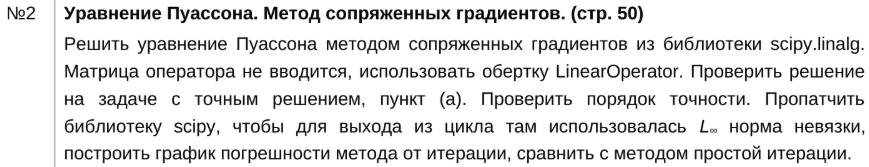

вариант (2.5):  
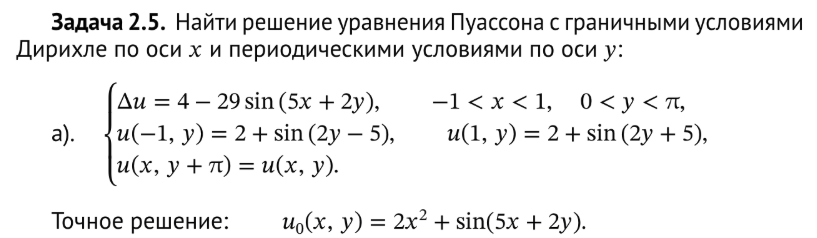

In [103]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse.linalg import LinearOperator, cg

Эти функции взял из лабораторной работы №1 (конечно-объёмная аппроксимация уравнения Пуассона и решение методом простой операции)

In [104]:
def u_exact(x, y):
    return 2.0 * x**2 + np.sin(5.0 * x + 2.0 * y)

def f_rhs(x, y):
    return 4.0 - 29.0 * np.sin(5.0 * x + 2.0 * y)

def mu(y):
    return 2.0 + np.sin(2.0 * y - 5.0)

def phi(y):
    return 2.0 + np.sin(2.0 * y + 5.0)

def get_tau(Nx, Ny, hx, hy):
    k_x = np.arange(1, Nx + 1)
    lam_x_vals = (4.0 / hx**2) * (np.sin((2 * k_x - 1) * np.pi / (4.0 * Nx)))**2
    lam_x_min, lam_x_max = np.min(lam_x_vals), np.max(lam_x_vals)
    
    k_y = np.arange(Ny)
    lam_y_vals = (4.0 / hy**2) * (np.sin(np.pi * k_y / Ny))**2
    lam_y_min, lam_y_max = np.min(lam_y_vals), np.max(lam_y_vals)
    
    lam_min = lam_x_min + lam_y_min
    lam_max = lam_x_max + lam_y_max
    
    return 2.0 / (lam_min + lam_max)

def compute_F(X, Y, hx):
    F = -f_rhs(X, Y)
    F[0, :] += 2.0 * mu(Y[0, :]) / hx**2
    F[-1, :] += 2.0 * phi(Y[-1, :]) / hx**2
    return F

def OpL(u, hx, hy):
    res = np.zeros_like(u)
    res[1:, :] += (u[1:, :] - u[:-1, :]) / hx**2
    res[:-1, :] += (u[:-1, :] - u[1:, :]) / hx**2
    res[:, 1:] += (u[:, 1:] - u[:, :-1]) / hy**2
    res[:, :-1] += (u[:, :-1] - u[:, 1:]) / hy**2
    res[0, :] += 2.0 * u[0, :] / hx**2
    res[-1, :] += 2.0 * u[-1, :] / hx**2
    res[:, 0] += (u[:, 0] - u[:, -1]) / hy**2
    res[:, -1] += (u[:, -1] - u[:, 0]) / hy**2
    return res

def solve_poisson_mpi(Nx, Ny, max_iter=50000, tol=1e-8):
    lx, ly = 2.0, np.pi
    hx, hy = lx / Nx, ly / Ny
    x = np.linspace(-1.0 + 0.5 * hx, 1.0 - 0.5 * hx, Nx)
    y = np.linspace(0.5 * hy, np.pi - 0.5 * hy, Ny)
    X, Y = np.meshgrid(x, y, indexing='ij')
    
    tau = get_tau(Nx, Ny, hx, hy)
    u = np.zeros((Nx, Ny))
    F = compute_F(X, Y, hx)
    u_exact_vals = u_exact(X, Y)
    
    history_res, history_err = [], []
    
    for k in range(max_iter):
        Lu = OpL(u, hx, hy)
        res = F - Lu
        res_norm_inf = np.max(np.abs(res))
        err_norm = np.max(np.abs(u - u_exact_vals))
        
        history_res.append(res_norm_inf)
        history_err.append(err_norm)
        
        if res_norm_inf < tol:
            break
        u += tau * res
        
    return u, X, Y, history_res, history_err, hx

Решение методом сопряжённых градиентов

In [105]:
def solve_poisson_cg(Nx, Ny, max_iter=50000, tol=1e-8):
    lx, ly = 2.0, np.pi
    hx, hy = lx / Nx, ly / Ny
    x = np.linspace(-1.0 + 0.5 * hx, 1.0 - 0.5 * hx, Nx)
    y = np.linspace(0.5 * hy, np.pi - 0.5 * hy, Ny)
    X, Y = np.meshgrid(x, y, indexing='ij')
    
    F = compute_F(X, Y, hx).flatten()
    u_exact_vals = u_exact(X, Y).flatten()
    
    def matvec(u_flat):
        u_2d = u_flat.reshape((Nx, Ny))
        res_2d = OpL(u_2d, hx, hy)
        return res_2d.flatten()
    
    A = LinearOperator((Nx * Ny, Nx * Ny), matvec=matvec, dtype=float)
    
    history_res, history_err = [], []
    solution_container = [None]
    
    class StopCG(Exception):
        pass

    # функция, которая вызывается после каждой итерации
    def callback(xk):
        r = F - A.matvec(xk)
        res_norm_inf = np.max(np.abs(r))
        err_norm = np.max(np.abs(xk - u_exact_vals))
        
        history_res.append(res_norm_inf)
        history_err.append(err_norm)
        solution_container[0] = xk.copy()
        
        # если L_inf невязка меньше допуска, прерываем цикл
        if res_norm_inf < tol:
            raise StopCG()

    try:
        cg(A, F, rtol=0, atol=0, maxiter=max_iter, callback=callback)
    except StopCG:
        pass

    u_flat = solution_container[0]
        
    u_2d = u_flat.reshape((Nx, Ny))
    return u_2d, X, Y, history_res, history_err, hx

In [106]:
Nx, Ny = 32, 32

u_mpi, X, Y, res_mpi, err_mpi, hx = solve_poisson_mpi(Nx, Ny)
print(f"МПИ: итераций - {len(res_mpi)}, макс. ошибка - {np.max(np.abs(u_mpi - u_exact(X, Y))):.4e}")

u_cg, _, _, res_cg, err_cg, _ = solve_poisson_cg(Nx, Ny)
print(f"CG: итераций - {len(res_cg)}, макс. ошибка - {np.max(np.abs(u_cg - u_exact(X, Y))):.4e}")

МПИ: итераций - 5417, макс. ошибка - 1.3834e-02
CG: итераций - 58, макс. ошибка - 1.3834e-02


График сходимости

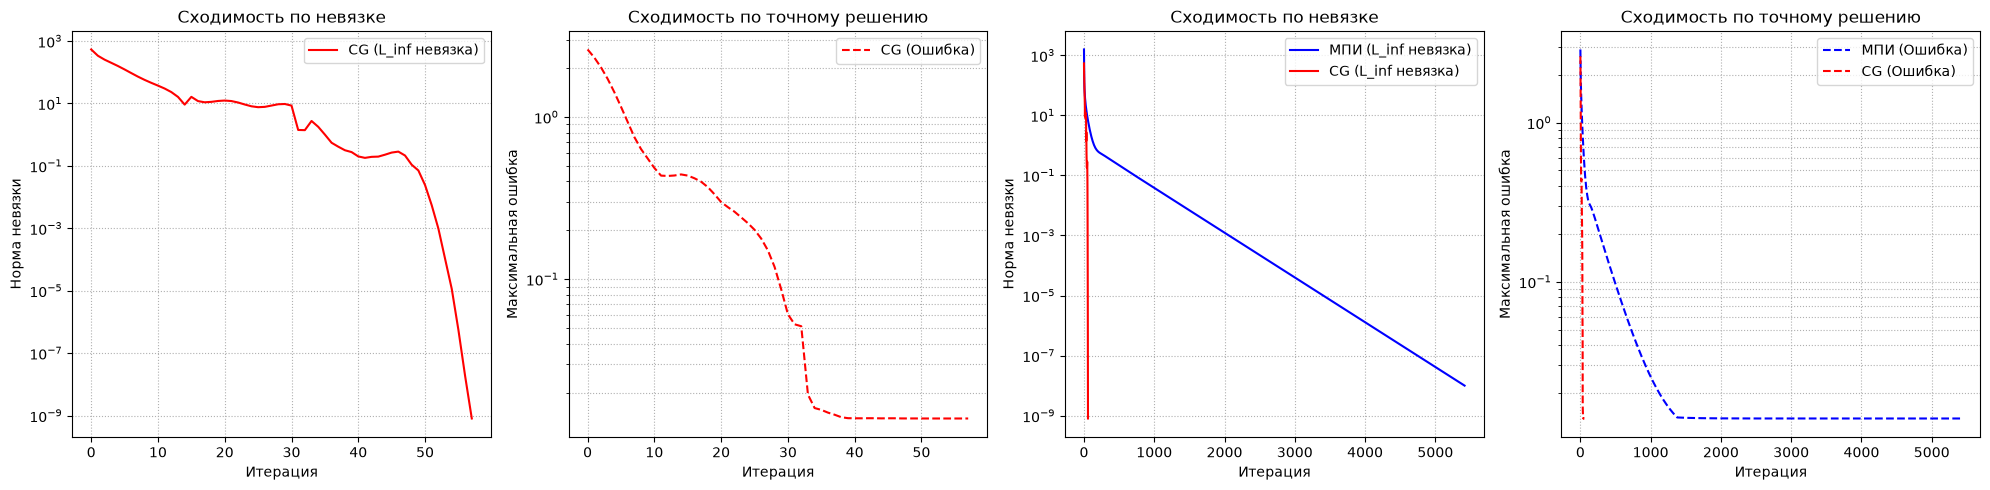

In [107]:
plt.figure(figsize=(20, 5))

plt.subplot(1, 4, 1)
plt.semilogy(res_cg, label='CG (L_inf невязка)', color='red')
plt.xlabel('Итерация')
plt.ylabel('Норма невязки')
plt.title('Сходимость по невязке')
plt.grid(True, which='both', ls=':')
plt.legend()

plt.subplot(1, 4, 2)
plt.semilogy(err_cg, label='CG (Ошибка)', color='red', linestyle='--')
plt.xlabel('Итерация')
plt.ylabel('Максимальная ошибка')
plt.title('Сходимость по точному решению')
plt.grid(True, which='both', ls=':')
plt.legend()

plt.subplot(1, 4, 3)
plt.semilogy(res_mpi, label='МПИ (L_inf невязка)', color='blue')
plt.semilogy(res_cg, label='CG (L_inf невязка)', color='red')
plt.xlabel('Итерация')
plt.ylabel('Норма невязки')
plt.title('Сходимость по невязке')
plt.grid(True, which='both', ls=':')
plt.legend()

plt.subplot(1, 4, 4)
plt.semilogy(err_mpi, label='МПИ (Ошибка)', color='blue', linestyle='--')
plt.semilogy(err_cg, label='CG (Ошибка)', color='red', linestyle='--')
plt.xlabel('Итерация')
plt.ylabel('Максимальная ошибка')
plt.title('Сходимость по точному решению')
plt.grid(True, which='both', ls=':')
plt.legend()

plt.tight_layout()
plt.show()

Проверка порядка точности

In [108]:
grids = [8, 16, 32, 64]
errors = []

for N in grids:
    u_n, X_g, Y_g, _, _, h = solve_poisson_cg(N, N, max_iter=100000, tol=1e-8)
    u_e = u_exact(X_g, Y_g)
    err = np.max(np.abs(u_n - u_e))
    errors.append(err)
    print(f"N = {N:2d}, h = {h:.4f}, ошибка = {err:.6e}")
    
for i in range(1, len(errors)):
    p = np.log2(errors[i-1] / errors[i])
    print(f"Порядок сходимости при переходе {grids[i-1]} -> {grids[i]}: p ~ {p:.2f}")

N =  8, h = 0.2500, ошибка = 2.087925e-01
N = 16, h = 0.1250, ошибка = 5.441191e-02
N = 32, h = 0.0625, ошибка = 1.383400e-02
N = 64, h = 0.0312, ошибка = 3.503621e-03
Порядок сходимости при переходе 8 -> 16: p ~ 1.94
Порядок сходимости при переходе 16 -> 32: p ~ 1.98
Порядок сходимости при переходе 32 -> 64: p ~ 1.98
